<a href="https://colab.research.google.com/github/R3ALITI3S/MachineLearningMiniProject/blob/Book/MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity recognition with healthy older people using a batteryless wearable sensor - ML Mini-Project
This is my submission for an Activity recognition classification, that aims to destinguish between four different physical activites of healthy older people using data collected from a batteryless wearable sensor. I will go through an exploration of the dataset, how the model was developed, which decicions i made regarding model selection and final evaluation and results.

The dataset contains measurements from 14 older people to classify four activities. One important characteristic is that the dataset is unbalanced as some activities have significantly more observations than others.

The possible class labels assigned for every sensor observation are:
1. Sitting on a bed: 3,296 observations
2. Sitting on a chair: 18,021 observations
3. Lying on a bed: 51,520 observations
4. Ambulating: 2,291 observations (where ambulating includes standing, walking around the room.)

The dataset: https://archive.ics.uci.edu/dataset/427/activity+recognition+with+healthy+older+people+using+a+batteryless+wearable+sensor

The placement of the electrode:

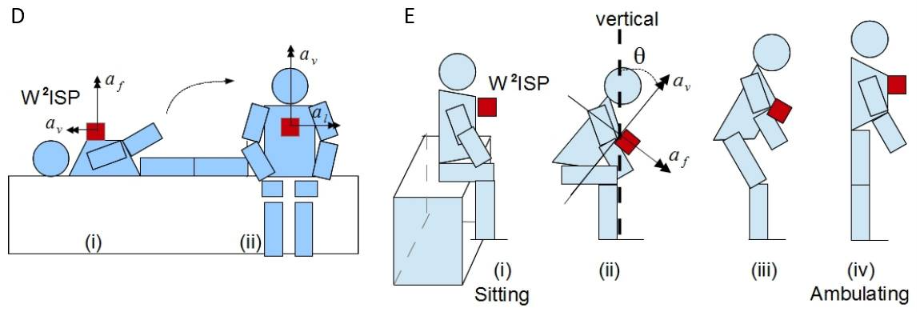

The image is taken from: _https://pmc.ncbi.nlm.nih.gov/articles/PMC4851060/_

# 0. Environment and imports
This cellblock below is for loading the relevant packages and imports. I imported `sklearn`, `numpy`, `pandas`, `matplotlib`, `pathlib` and `seaborn`.

`sklearn (Scikit-learn):` For ML, data preprocessing, model training, hyperparameter tuning, cross-validation and model evaluation

`numpy:` For numerical operations, working with arrays and mathematical calculations

`pandas:` Used for loading, organizing, cleaning and manipulating the dataset using DataFrames

`matplotlib:` To create visualizations, such as plots, histograms, and charts

`pathlib:` Handeling file paths, and making it easier to locate and load datasets

`Seaborn:` For statistical data visualizations, which helps identify distributions, patterns, correlations and relationships between and across features


In [38]:
# Data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Paths
from pathlib import Path

# Data splitting and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)

# Data preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer,
    PolynomialFeatures
)

# Pipelines
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier

# Dimensionality reduction and feature selection
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectFromModel

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1) Setup and data loading
The data is downloaded from: https://archive.ics.uci.edu/dataset/427/activity+recognition+with+healthy+older+people+using+a+batteryless+wearable+sensor.

The dataset consists of multiple individual files containing recordings from 14 participants, divided into two clinical room settings: `1_Dataset` and `S2_Dataset`. Room 1 uses four RFID antennas, while Room 2 uses three.

Each file contains 9 columns: 8 sensor measurements and 1 activity label. `pathlib` for locate the downloaded files, and pandas to read them individually. Then assign column names and add them to their specefic folders.

Then combine all training instances are fit into a `DataFrame` using `pd.concat()`. Then a `df.head()` to verify the data is loaded correctly.



In [12]:
np.random.seed(42)          # reproducible results (Ch. 2)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [40]:
# Import the dataset
base_folder = Path(r"C:\Users\nield\Desktop\GitHub\MachineLearningMiniProject\activity+recognition+with+healthy+older+people+using+a+batteryless+wearable+sensor")

# Columns
columns = ["time", "accel_frontal", "accel_vertical", "accel_lateral", "antenna_id", "RSSI", "phase", "frequency", "activity"]

# Open the dataset
dataframes = []

for folder_name in ["S1_Dataset", "S2_Dataset"]:
    for file in (base_folder / folder_name).iterdir():
        if file.is_file():
            try:
                temp_df = pd.read_csv(file, header=None, sep=None, engine="python")

                if temp_df.shape[1] == len(columns):
                    temp_df.columns = columns
                    temp_df["subject_folder"] = folder_name
                    temp_df["source_file"] = file.name
                    dataframes.append(temp_df)
            except Exception:
                pass

df = pd.concat(dataframes, ignore_index=True)

# Prints, can be removed later.
print("The shape of the dataset", df.shape)
df.head() # show the data in a table

The shape of the dataset (75128, 11)


,time,accel_frontal,accel_vertical,accel_lateral,antenna_id,RSSI,phase,frequency,activity,subject_folder,source_file
0,0.00,0.27203,1.00820,-0.082102,1,-63.5,2.4252,924.25,1,S1_Dataset,d1p01M
1,0.50,0.27203,1.00820,-0.082102,1,-63.0,4.7369,921.75,1,S1_Dataset,d1p01M
2,1.50,0.44791,0.91636,-0.013684,1,-63.5,3.0311,923.75,1,S1_Dataset,d1p01M
3,1.75,0.44791,0.91636,-0.013684,1,-63.0,2.0371,921.25,1,S1_Dataset,d1p01M
4,2.50,0.34238,0.96229,-0.059296,1,-63.5,5.8920,920.25,1,S1_Dataset,d1p01M


# 2) EDA - Explore the data
In the next step we look at the data before modelling, therefore exploring the trainingset before deciding on transformations, or else information from the test data leaks into the decicions *(data snooping bias)*. Here we do a first look at the whole table to understand the problem, and every *fitted* decision (medians, scaling, which columns are skewed) is made later using only the training data

The code below cheks for missing data. - We see that there is no missing values per column

In [14]:
# Prints a summary of the DataFrame
df.info()
print("\nMissing values per column:\n", df.isna().sum())

# generates a quick statistical summary of the columns in a DataFrame
df.describe()          # scale and range of each feature

<class 'pandas.DataFrame'>
RangeIndex: 75128 entries, 0 to 75127
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   time            75128 non-null  float64
 1   accel_frontal   75128 non-null  float64
 2   accel_vertical  75128 non-null  float64
 3   accel_lateral   75128 non-null  float64
 4   antenna_id      75128 non-null  int64  
 5   RSSI            75128 non-null  float64
 6   phase           75128 non-null  float64
 7   frequency       75128 non-null  float64
 8   activity        75128 non-null  int64  
 9   subject_folder  75128 non-null  str    
 10  source_file     75128 non-null  str    
dtypes: float64(7), int64(2), str(2)
memory usage: 6.3 MB

Missing values per column:
 time              0
accel_frontal     0
accel_vertical    0
accel_lateral     0
antenna_id        0
RSSI              0
phase             0
frequency         0
activity          0
subject_folder    0
source_file       0
dtype: int

,time,accel_frontal,accel_vertical,accel_lateral,antenna_id,RSSI,phase,frequency,activity
count,75128.000000,75128.000000,75128.000000,75128.000000,75128.000000,75128.000000,75128.000000,75128.000000,75128.000000
mean,299.080416,0.714211,0.345199,-0.217477,2.409581,-58.277253,3.157279,922.670536,2.528378
std,257.503002,0.404585,0.419041,0.438219,1.102165,5.174083,2.182257,1.679093,0.864258
min,0.000000,-0.748080,-0.553490,-1.336400,1.000000,-72.000000,0.000000,920.250000,1.000000
25%,121.250000,0.342380,-0.002297,-0.184730,1.000000,-62.000000,1.032400,921.250000,2.000000
50%,250.715000,0.682420,0.215880,-0.070699,3.000000,-58.000000,2.767300,922.750000,3.000000
75%,402.500000,1.104500,0.858940,0.031928,3.000000,-56.000000,5.358575,924.250000,3.000000
max,1739.400000,1.503200,2.030200,1.217800,4.000000,-38.500000,6.281700,925.750000,4.000000


**What to look for:** the features have very different ranges (e.g. `frequency` is around 900 while accelerations are around ±1).

`info()` also tells us whether there are missing values; even if there are none, we still put an imputer into the pipeline so the pipeline is safe on new data. See later on.

**Why look at class balance:** if one class were 90% of the data, "accuracy" would be misleading (Ch. 3 warns that accuracy is a poor metric for skewed datasets).

## Class distribution check
Here, if the classes are clearly imbalanced, we need to remember that when reading results, and we use **stratified** splits so each split keeps the same class proportions.

activity
1    0.218
2    0.065
3    0.686
4    0.030
Name: proportion, dtype: float64


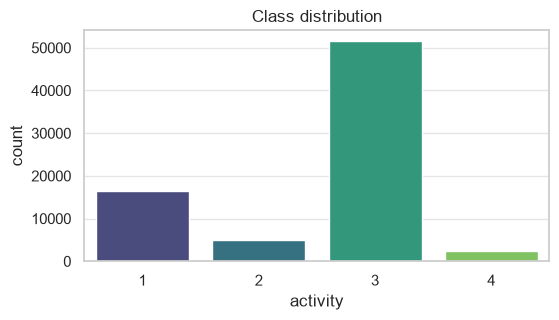

In [15]:
# See the class distribution
print(df["activity"].value_counts(normalize=True).sort_index().round(3))
plt.figure(figsize=(6, 3))
sns.countplot(x="activity", data=df, palette="viridis")
plt.title("Class distribution")
plt.show()

When looking at the plot, activity 3 have quite a lot of data compared to the rest. Therefore `Stratify` is going to be have to be used. So preserve the proportion of each activity across the training, validation, and test sets. This ensures that all activities are represented fairly in each split.

## Skewed data?
**Why skewness matters** Ch. 2 says that when a feature has a heavy tail, most ML algorithms do not work as well, and should transform it so it is more symmetric (the book uses a **log** transform). We measure skewness with `.skew()`.

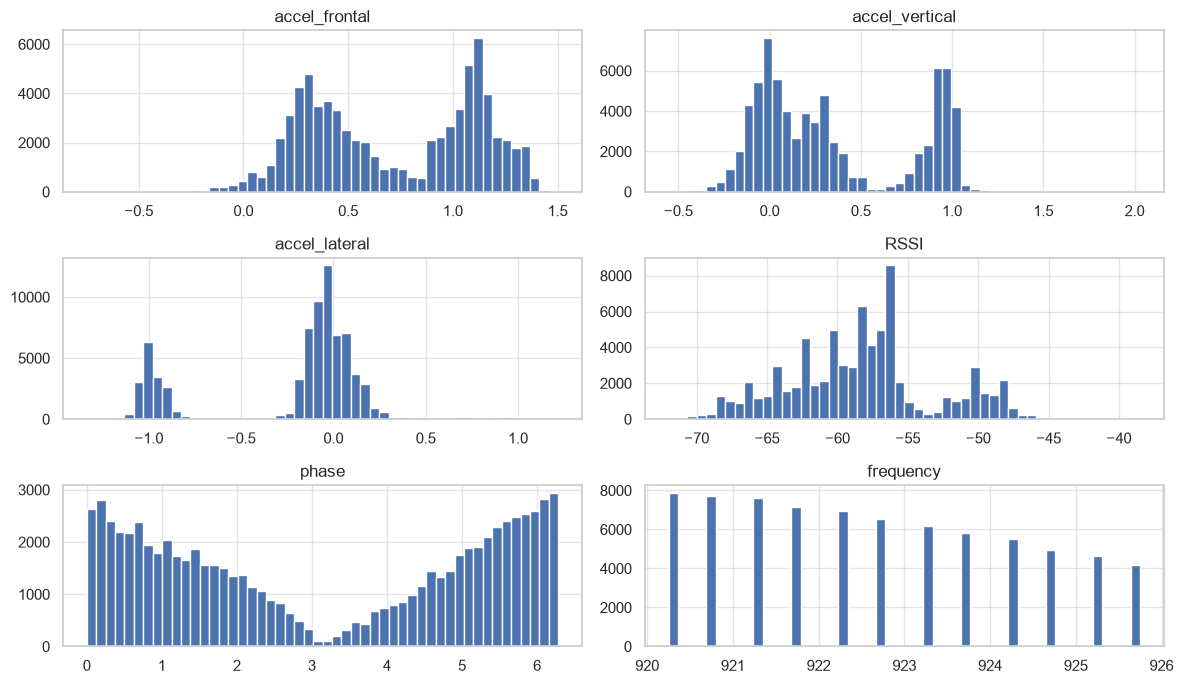

Skewness (0 = symmetric):
accel_frontal    -0.07
accel_vertical    0.48
accel_lateral    -0.78
RSSI              0.23
phase             0.01
frequency         0.23
dtype: float64


In [16]:
# Histograms: shows scale and skewness of each numeric feature (Ch. 2 uses hist() for this)
num_cols = ["accel_frontal", "accel_vertical", "accel_lateral", "RSSI", "phase", "frequency"] # The class is above
df[num_cols].hist(bins=50, figsize=(12, 7))
plt.tight_layout()
plt.show()

print("Skewness (0 = symmetric):")
print(df[num_cols].skew().round(2))

When looking at the features plotted. The features had very different scales and had different ranges.

## Pairwise feature relationships

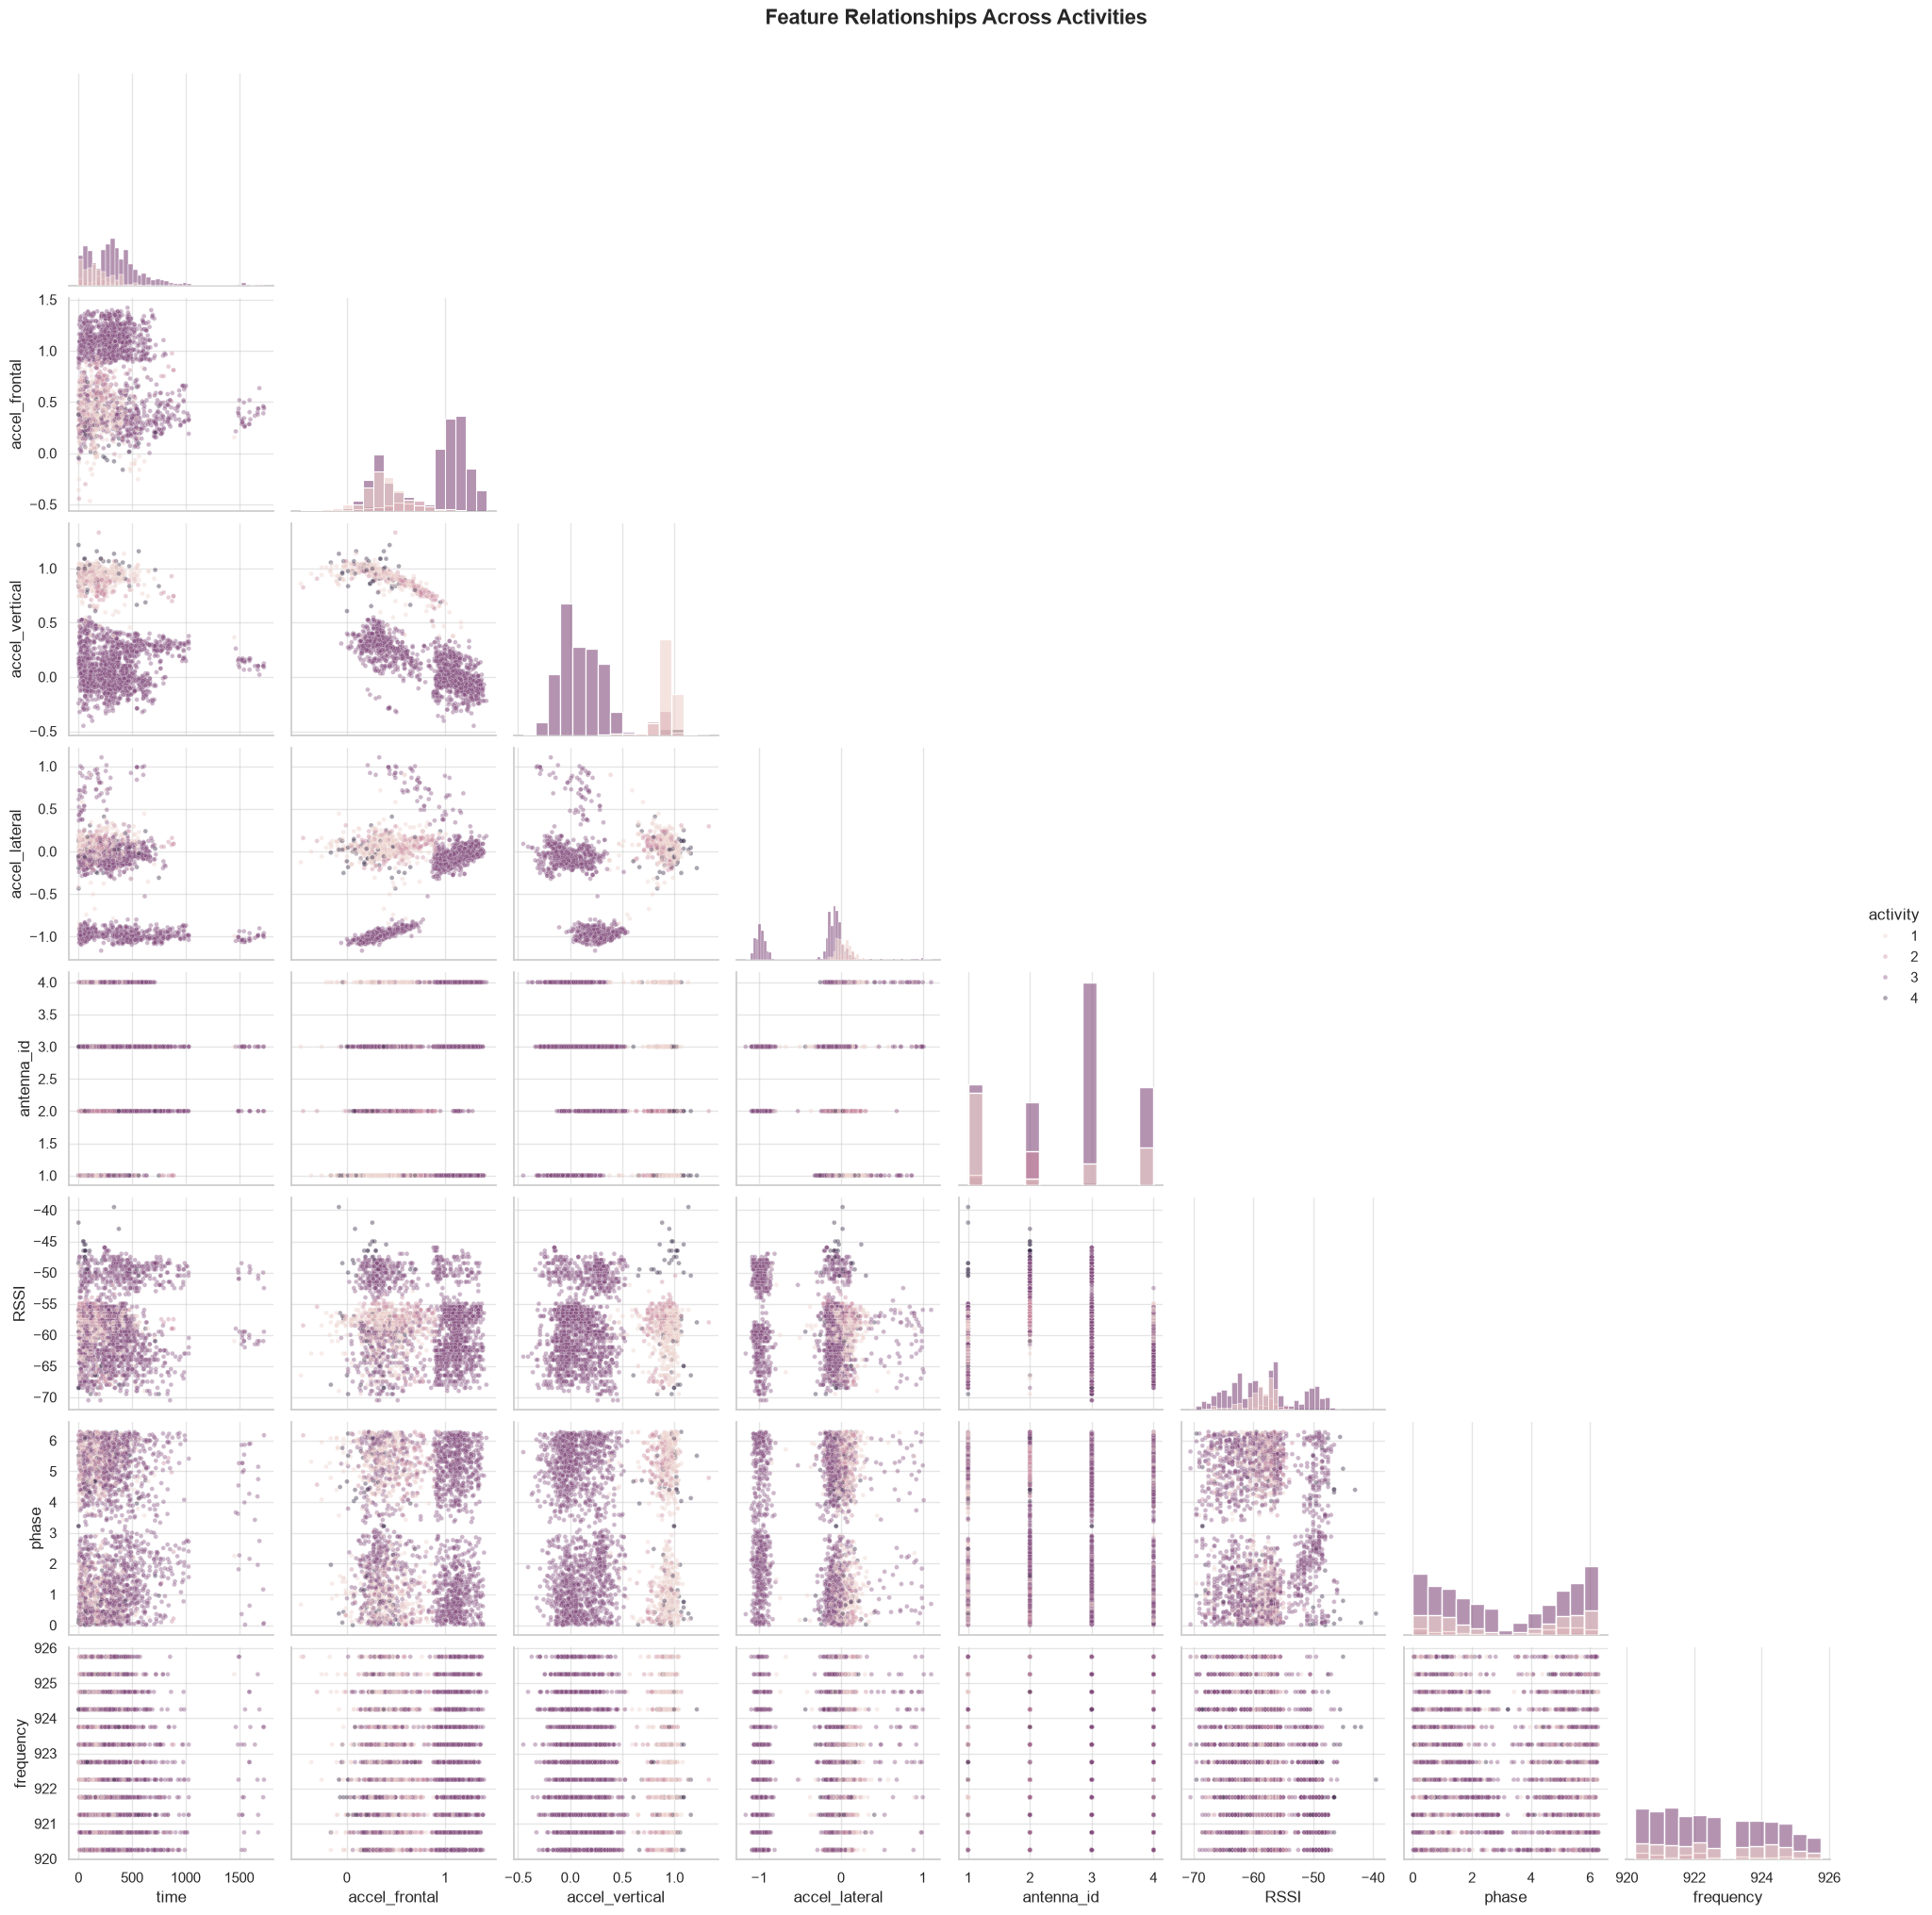

In [43]:
# Prepare data for visualization
plot_data = df.drop(columns=["subject_folder", "source_file"], errors="ignore").copy()

# Set visualization style
sns.set_theme(style="whitegrid", context="notebook")

# Create pairplot
g = sns.pairplot(
    plot_data.sample(n=min(2500, len(plot_data)), random_state=42),
    hue="activity",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.4, "s": 12},
    diag_kws={"alpha": 0.6}
)

# Add title
g.figure.suptitle(
    "Feature Relationships Across Activities",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.show()


## Confusion Matrix

**Why:** Ch. 2 uses the correlation matrix to spot features linked to the target and features that duplicate each other. Remember the book's warning: the correlation coefficient only measures **linear** relationships. A feature with ~0 correlation to `activity` can still be very useful in a non-linear model, so we do not drop features based on this plot alone.

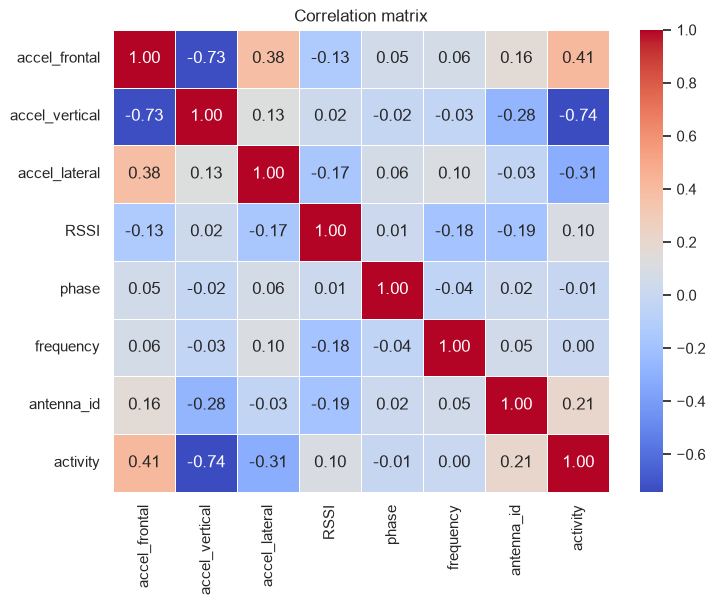

In [17]:
# Correlation matrix (Ch. 2: corr()) - to see which features move together
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols + ["antenna_id", "activity"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation matrix")
plt.show()

Here is a visualization of the axies:

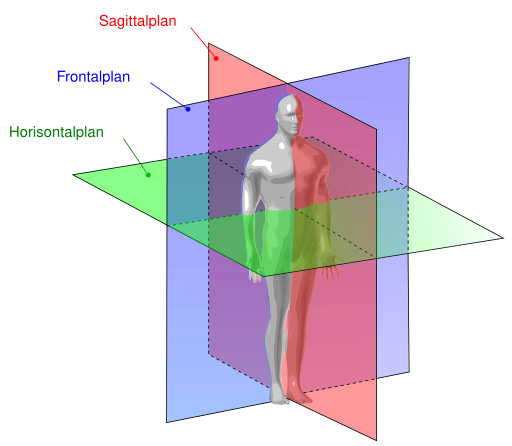

Picture taken from: _https://lex.dk/sagittalplan_

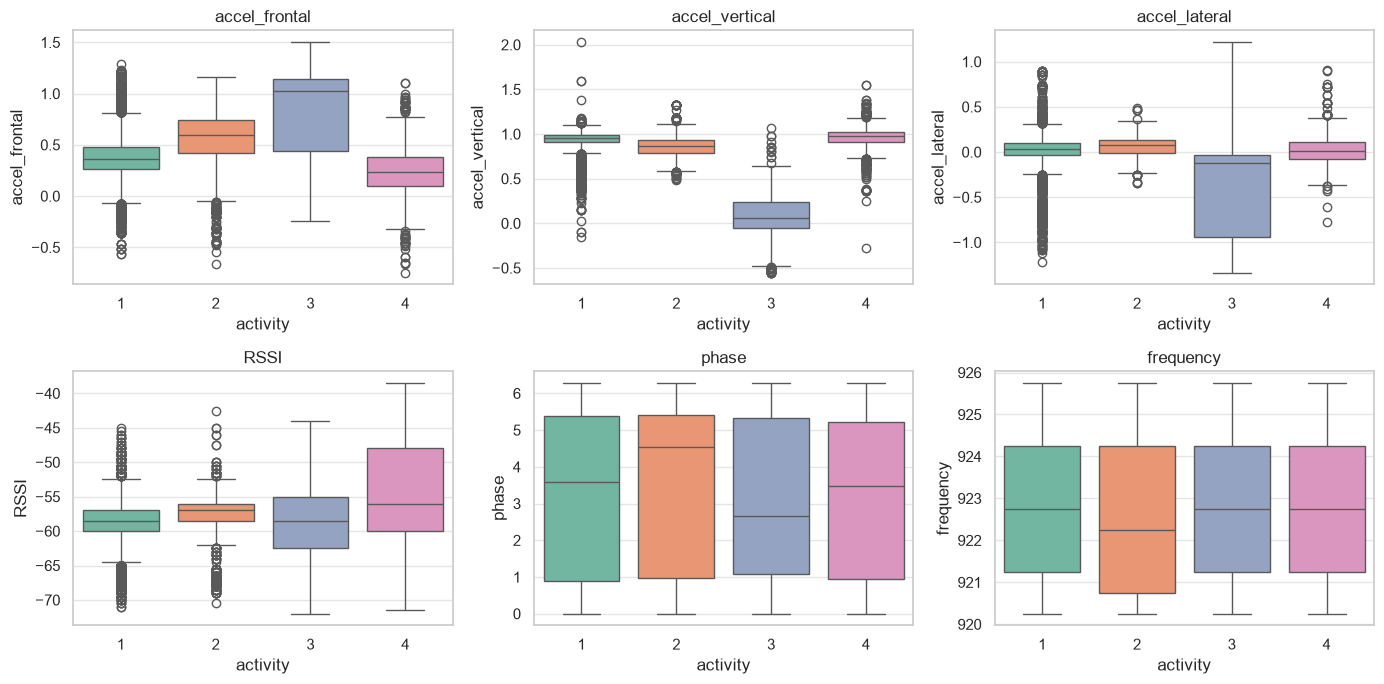

In [18]:
# Which features separate the activities?  (box plots per class)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x="activity", y=col, data=df, palette="Set2", ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

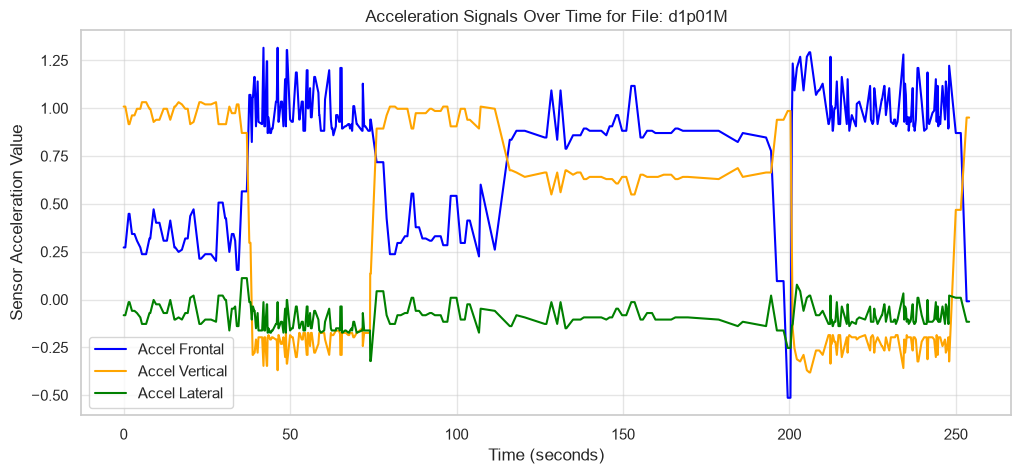

In [19]:
# We filter the data for a single sample file to inspect continuous sensor readings over time
sample_file_name = df['source_file'].iloc[0]
subset_df = df[df['source_file'] == sample_file_name].head(1000)

plt.figure(figsize=(12, 5)) # for the plot
plt.plot(subset_df['time'], subset_df['accel_frontal'], label='Accel Frontal', color='blue')
plt.plot(subset_df['time'], subset_df['accel_vertical'], label='Accel Vertical', color='orange')
plt.plot(subset_df['time'], subset_df['accel_lateral'], label='Accel Lateral', color='green')
plt.title(f'Acceleration Signals Over Time for File: {sample_file_name}')
plt.xlabel('Time (seconds)')
plt.ylabel('Sensor Acceleration Value')
plt.legend()
plt.show()

# 3. Training LOOK
- **Training set:** The model learns from it
- **Validation ("dev") set:** used to compare models and hyperparameters. (if used the training for it, tuning would be happening and the final score would bee too optimistic)
- **Test set:** touched only **once** at the end to estimate how the model works on new unseen data (generalization error)

**Cross-validation instead of one fixed dev set:** guideline 3 asks us to use cross-validation on training+dev. Ch. 2 explains that K-fold CV splits the training+dev data into K folds and, in turn, uses each fold as the validation set. This gives a more reliable estimate than a single dev split and uses all the data. So we split once into **train+dev (85%)** and **test (15%)**; the dev sets are the CV folds.

**Why `stratify=y`:** Ch. 2 introduces *stratified sampling*, so every split has the same class proportions as the full data and the test set is representative.


In [20]:
X = df.drop(columns=["activity", "source_file", "time"])
y = df["activity"]

X_traindev, X_test, y_traindev, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y)

print("train+dev:", X_traindev.shape, " test:", X_test.shape)
print(y_traindev.value_counts(normalize=True).sort_index().round(3).to_dict())
print(y_test.value_counts(normalize=True).sort_index().round(3).to_dict())

train+dev: (63858, 8)  test: (11270, 8)
{1: 0.218, 2: 0.065, 3: 0.686, 4: 0.03}
{1: 0.218, 2: 0.065, 3: 0.686, 4: 0.031}


`time` is dropped, as it tells os nothing about the person's posture. So if kept then it could let a model learn when in a recording things happen, whitch would not generalize to new recordings.

> **Honest limitation:** consecutive rows from the same recording are very similar. A random split puts neighbouring rows in both train and test, which tends to make scores look better than they would on a completely new person. This notebook follows the book's stratified random split; Section 11 comes back to this.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # stratified K-fold (Ch. 3)

# 4. Preprocessing pipeline

In [22]:
# Visualized earlier up in secotion 2
skew = X_traindev[num_cols].skew()
print(skew.round(2))
skewed_cols = [c for c in num_cols if abs(skew[c]) > 0.5]
other_num_cols = [c for c in num_cols if c not in skewed_cols]
print("\nTreated as skewed (|skew| > 0.5):", skewed_cols)
print("Other numeric:", other_num_cols)

accel_frontal    -0.07
accel_vertical    0.48
accel_lateral    -0.78
RSSI              0.23
phase             0.01
frequency         0.23
dtype: float64

Treated as skewed (|skew| > 0.5): ['accel_lateral']
Other numeric: ['accel_frontal', 'accel_vertical', 'RSSI', 'phase', 'frequency']


In [23]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

skewed_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("signed_log", FunctionTransformer(signed_log, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])
num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

transformers = [("cat", cat_pipe, ["antenna_id"])]
if skewed_cols:     transformers.append(("skewed", skewed_pipe, skewed_cols))
if other_num_cols:  transformers.append(("num", num_pipe, other_num_cols))
preprocess = ColumnTransformer(transformers)

# Sanity check on the training data: shape and a before/after look at skew
Xt = preprocess.fit_transform(X_traindev)
print("Features after preprocessing:", Xt.shape[1])
print("Skew after (numeric columns only):")
print(pd.DataFrame(Xt, columns=preprocess.get_feature_names_out()).filter(regex="^(skewed|num)__").skew().round(2))

Features after preprocessing: 10
Skew after (numeric columns only):
skewed__accel_lateral   -0.63
num__accel_frontal      -0.07
num__accel_vertical      0.48
num__RSSI                0.23
num__phase               0.01
num__frequency           0.23
dtype: float64


# 5 Baseline
A `DummyClassifier` that *always* predicts the most frequent class tells us the "do nothging" accuracy that every real model must beat (chapter 3.)

We use **accuracy** and **macro-F1** (the average F1 over classes, which treats each class equally, so it is not fooled by class imbalance; F1 is from Ch. 3).

In [24]:
scoring = {"acc": "accuracy", "f1_macro": "f1_macro"}
results = {}   # name -> (cv accuracy, cv macro-F1)

def cv_report(name, estimator, X=X_traindev, y=y_traindev):
    s = cross_validate(estimator, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    results[name] = (s["test_acc"].mean(), s["test_f1_macro"].mean())
    print(f"{name:40s} CV accuracy = {results[name][0]:.4f}   CV macro-F1 = {results[name][1]:.4f}")

dummy = Pipeline([("prep", preprocess), ("clf", DummyClassifier(strategy="most_frequent"))])
cv_report("Baseline (most frequent class)", dummy)

Baseline (most frequent class)           CV accuracy = 0.6858   CV macro-F1 = 0.2034


# 6) Model 1. Logistic Regresstion (chap 4.)
A linear model:
- computes the weighted sum of the features and turns them into class probabilities with the softmax function.
- It can only draw linear bondaries, so the simplest yipie

In [25]:
logreg = Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=2000))])
logreg_grid = GridSearchCV(logreg, {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
                           cv=cv, scoring="f1_macro", n_jobs=-1, return_train_score=True)
logreg_grid.fit(X_traindev, y_traindev)

res = pd.DataFrame(logreg_grid.cv_results_)[["param_clf__C", "mean_train_score", "mean_test_score"]]
print(res.round(4).to_string(index=False))
print("\nBest:", logreg_grid.best_params_, " CV macro-F1 =", round(logreg_grid.best_score_, 4))
results["Logistic Regression (tuned C)"] = (
    cross_validate(logreg_grid.best_estimator_, X_traindev, y_traindev, cv=cv, scoring="accuracy")["test_score"].mean(),
    logreg_grid.best_score_)

 param_clf__C  mean_train_score  mean_test_score
        0.001            0.7207           0.7204
        0.010            0.7966           0.7957
        0.100            0.8040           0.8032
        1.000            0.8072           0.8065
       10.000            0.8072           0.8060
      100.000            0.8070           0.8060

Best: {'clf__C': 1}  CV macro-F1 = 0.8065


I compared `mean_train_score` and `mean_test_score` (the validation folds).

A large gap means overfitting.. and low means underfitting - These data sets are very close

## 6.1 Polynmial features (chap.4)

In [26]:
logreg_poly = Pipeline([
    ("prep", preprocess),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("scale", StandardScaler()),       # re-scale: squares/products have new ranges (Ch. 4 does the same)
    ("clf", LogisticRegression(max_iter=3000)),
])
logreg_poly_grid = GridSearchCV(
    logreg_poly, {"poly__degree": [2, 3], "clf__C": [0.01, 0.1, 1]},
    cv=cv, scoring="f1_macro", n_jobs=-1, return_train_score=True)
logreg_poly_grid.fit(X_traindev, y_traindev)

res = pd.DataFrame(logreg_poly_grid.cv_results_)[["param_poly__degree", "param_clf__C", "mean_train_score", "mean_test_score"]]
print(res.round(4).to_string(index=False))
print("\nBest:", logreg_poly_grid.best_params_, " CV macro-F1 =", round(logreg_poly_grid.best_score_, 4))
results["Logistic Regression + polynomial features"] = (
    cross_validate(logreg_poly_grid.best_estimator_, X_traindev, y_traindev, cv=cv, scoring="accuracy")["test_score"].mean(),
    logreg_poly_grid.best_score_)

 param_poly__degree  param_clf__C  mean_train_score  mean_test_score
                  2          0.01            0.8534           0.8527
                  3          0.01            0.8728           0.8696
                  2          0.10            0.8598           0.8584
                  3          0.10            0.8861           0.8788
                  2          1.00            0.8643           0.8609
                  3          1.00            0.8918           0.8842

Best: {'clf__C': 1, 'poly__degree': 3}  CV macro-F1 = 0.8842


# 7 Model 2: Support Vector Machine (SVM) (chap. 5)

In [27]:
SVM_SUBSAMPLE = 6000     # lower this if the grid search is too slow, raise it if you have time
if len(X_traindev) > SVM_SUBSAMPLE:
    X_svm, _, y_svm, _ = train_test_split(X_traindev, y_traindev, train_size=SVM_SUBSAMPLE,
                                          random_state=RANDOM_STATE, stratify=y_traindev)
else:
    X_svm, y_svm = X_traindev, y_traindev
print("SVM tuning subsample:", X_svm.shape)

svm = Pipeline([("prep", preprocess), ("clf", SVC())])
svm_grid_params = [
    {"clf__kernel": ["rbf"],  "clf__C": [0.1, 1, 10, 100], "clf__gamma": [0.01, 0.1, 1]},
    {"clf__kernel": ["poly"], "clf__C": [0.1, 1, 10], "clf__degree": [2, 3], "clf__coef0": [0, 1], "clf__gamma": ["scale"]},
]
svm_grid = GridSearchCV(svm, svm_grid_params, cv=cv, scoring="f1_macro", n_jobs=-1, return_train_score=True)
svm_grid.fit(X_svm, y_svm)

res = pd.DataFrame(svm_grid.cv_results_)
cols = [c for c in res.columns if c.startswith("param_")] + ["mean_train_score", "mean_test_score"]
print(res[cols].sort_values("mean_test_score", ascending=False).head(10).round(4).to_string(index=False))
print("\nBest:", svm_grid.best_params_, " CV macro-F1 (subsample) =", round(svm_grid.best_score_, 4))

SVM tuning subsample: (6000, 8)
 param_clf__C param_clf__gamma param_clf__kernel  param_clf__coef0  param_clf__degree  mean_train_score  mean_test_score
        100.0              0.1               rbf               NaN                NaN            0.9335           0.8722
         10.0                1               rbf               NaN                NaN            0.9855           0.8616
         10.0            scale              poly               1.0                3.0            0.9145           0.8604
         10.0              0.1               rbf               NaN                NaN            0.8837           0.8593
         10.0            scale              poly               0.0                3.0            0.8971           0.8575
          1.0            scale              poly               1.0                3.0            0.8774           0.8570
         10.0            scale              poly               1.0                2.0            0.8726           0.8558


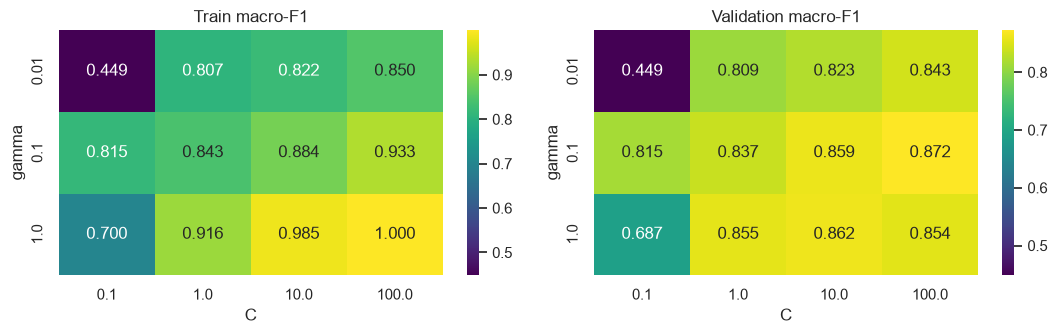

In [28]:
rbf = res[res["param_clf__kernel"] == "rbf"]
table = rbf.pivot_table(index="param_clf__gamma", columns="param_clf__C", values="mean_test_score")
train_table = rbf.pivot_table(index="param_clf__gamma", columns="param_clf__C", values="mean_train_score")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.heatmap(train_table.astype(float), annot=True, fmt=".3f", cmap="viridis", ax=axes[0]); axes[0].set_title("Train macro-F1")
sns.heatmap(table.astype(float), annot=True, fmt=".3f", cmap="viridis", ax=axes[1]); axes[1].set_title("Validation macro-F1")
for a in axes: a.set_xlabel("C"); a.set_ylabel("gamma")
plt.tight_layout(); plt.show()

In [29]:
# Score the best SVM settings with the same 5-fold CV, on the same subsample, so it is comparable to the others
best_svm = svm_grid.best_estimator_
cv_report("SVM (tuned, subsample)", best_svm, X_svm, y_svm)

SVM (tuned, subsample)                   CV accuracy = 0.9703   CV macro-F1 = 0.8722


# 8) Model 3: Random Forest (chap. 6-7)
A Decision tree:
- splits the data with a series of yes/no question on single features.
- A single big (deep) tree overfits
- A random forest trains many trees on random bootstrap samples with random subsets of features and averages theirt votes which reduces variance (bagging).
- The trees need no feature scaling, handle non-linear relationshios and interations, and give feature importances.

In [30]:
rf = Pipeline([("prep", preprocess), ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
rf_params = {
    "clf__n_estimators": [50, 100, 200],
    "clf__max_depth": [5, 10, 20, None],
    "clf__min_samples_leaf": [1, 5, 20, 50],
    "clf__max_features": ["sqrt", 0.5, 1.0],
}
rf_search = RandomizedSearchCV(rf, rf_params, n_iter=12, cv=cv, scoring="f1_macro",
                               random_state=RANDOM_STATE, n_jobs=1, return_train_score=True)
rf_search.fit(X_traindev, y_traindev)

res = pd.DataFrame(rf_search.cv_results_)
cols = [c for c in res.columns if c.startswith("param_")] + ["mean_train_score", "mean_test_score"]
print(res[cols].sort_values("mean_test_score", ascending=False).head(8).round(4).to_string(index=False))
print("\nBest:", rf_search.best_params_, " CV macro-F1 =", round(rf_search.best_score_, 4))
best_rf = rf_search.best_estimator_
results["Random Forest (tuned)"] = (
    cross_validate(best_rf, X_traindev, y_traindev, cv=cv, scoring="accuracy", n_jobs=1)["test_score"].mean(),
    rf_search.best_score_)

 param_clf__n_estimators  param_clf__min_samples_leaf param_clf__max_features param_clf__max_depth  mean_train_score  mean_test_score
                      50                            1                     1.0                 None            0.9995           0.9473
                     100                            1                     1.0                   20            0.9918           0.9453
                     200                            5                     1.0                   10            0.9231           0.9080
                      50                            5                     0.5                   10            0.9147           0.9032
                      50                           20                     1.0                   10            0.9025           0.8959
                     200                           20                     0.5                   10            0.8974           0.8904
                      50                           20         

# 9

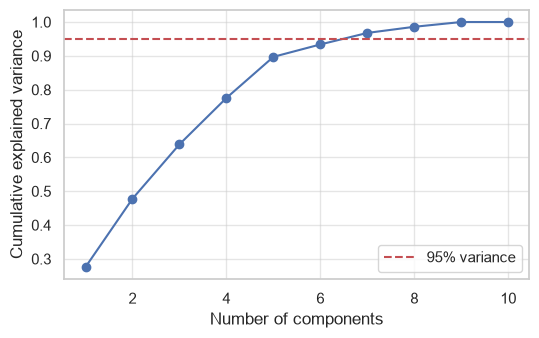

Components needed for 95% variance: 7 of 10


In [31]:
# --- PCA: how many components for how much variance? ---
Xt = preprocess.fit_transform(X_traindev)
pca_full = PCA().fit(Xt)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(cumvar) + 1), cumvar, marker="o")
plt.axhline(0.95, color="r", ls="--", label="95% variance")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance"); plt.legend(); plt.show()
print("Components needed for 95% variance:", int(np.argmax(cumvar >= 0.95)) + 1, "of", Xt.shape[1])

In [32]:
# --- L1 selection: which features get weight zero? ---
for C in [0.001, 0.01, 0.1]:
    sel = SelectFromModel(LinearSVC(penalty="l1", dual=False, C=C, max_iter=5000)).fit(Xt, y_traindev)
    names = preprocess.get_feature_names_out()
    print(f"C={C}: keeps {sel.get_support().sum()} of {len(names)} -> {list(names[sel.get_support()])}")

C=0.001: keeps 7 of 10 -> ['cat__antenna_id_2', 'cat__antenna_id_4', 'skewed__accel_lateral', 'num__accel_frontal', 'num__accel_vertical', 'num__RSSI', 'num__frequency']
C=0.01: keeps 10 of 10 -> ['cat__antenna_id_1', 'cat__antenna_id_2', 'cat__antenna_id_3', 'cat__antenna_id_4', 'skewed__accel_lateral', 'num__accel_frontal', 'num__accel_vertical', 'num__RSSI', 'num__phase', 'num__frequency']
C=0.1: keeps 10 of 10 -> ['cat__antenna_id_1', 'cat__antenna_id_2', 'cat__antenna_id_3', 'cat__antenna_id_4', 'skewed__accel_lateral', 'num__accel_frontal', 'num__accel_vertical', 'num__RSSI', 'num__phase', 'num__frequency']


In [33]:
rf_kwargs = {k.replace("clf__", ""): v for k, v in rf_search.best_params_.items()}
make_rf = lambda: RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **rf_kwargs)

rf_all   = Pipeline([("prep", preprocess), ("clf", make_rf())])
rf_pca   = Pipeline([("prep", preprocess), ("pca", PCA(n_components=0.95)), ("clf", make_rf())])
rf_lasso = Pipeline([("prep", preprocess),
                     ("select", SelectFromModel(LinearSVC(penalty="l1", dual=False, C=0.1, max_iter=5000))),
                     ("clf", make_rf())])

cv_report("Random Forest, all features", rf_all)
cv_report("Random Forest, PCA (95% variance)", rf_pca)
cv_report("Random Forest, L1 feature selection", rf_lasso)

Random Forest, all features              CV accuracy = 0.9871   CV macro-F1 = 0.9473
Random Forest, PCA (95% variance)        CV accuracy = 0.9825   CV macro-F1 = 0.9354
Random Forest, L1 feature selection      CV accuracy = 0.9871   CV macro-F1 = 0.9473


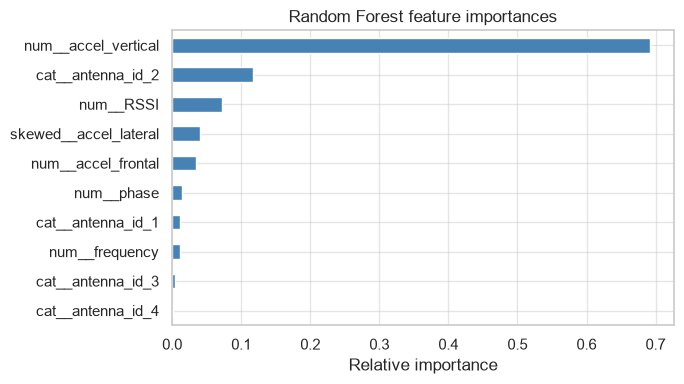

In [34]:
best_rf.fit(X_traindev, y_traindev)
names = best_rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_rf.named_steps["clf"].feature_importances_, index=names).sort_values()
imp.plot(kind="barh", figsize=(7, 4), color="steelblue")
plt.title("Random Forest feature importances"); plt.xlabel("Relative importance"); plt.tight_layout(); plt.show()

# 10) Choosing the best model and test it!

In [35]:
summary = pd.DataFrame(results, index=["CV accuracy", "CV macro-F1"]).T.sort_values("CV macro-F1", ascending=False)
summary.round(4)

,CV accuracy,CV macro-F1
"Random Forest, all features",0.9871,0.9473
"Random Forest, L1 feature selection",0.9871,0.9473
Random Forest (tuned),0.9871,0.9473
"Random Forest, PCA (95% variance)",0.9825,0.9354
Logistic Regression + polynomial features,0.9733,0.8842
"SVM (tuned, subsample)",0.9703,0.8722
Logistic Regression (tuned C),0.9563,0.8065
Baseline (most frequent class),0.6858,0.2034


In [36]:

# Candidates that were trained on the FULL train+dev data (the SVM was tuned on a subsample, so it is refit below)
candidates = {
    "Logistic Regression (tuned C)": logreg_grid.best_estimator_,
    "Logistic Regression + polynomial features": logreg_poly_grid.best_estimator_,
    "Random Forest (tuned)": best_rf,
}
# Choose the winner by CV macro-F1 among all models in the table
best_name = summary.index[0]
print("Best by CV macro-F1:", best_name)

if best_name.startswith("SVM"):
    final_model = svm_grid.best_estimator_.fit(X_traindev, y_traindev)   # refit on all train+dev
elif best_name in candidates:
    final_model = candidates[best_name]
else:  # one of the Random-Forest feature-reduction variants
    final_model = {"Random Forest, all features": rf_all, "Random Forest, PCA (95% variance)": rf_pca,
                   "Random Forest, L1 feature selection": rf_lasso}[best_name].fit(X_traindev, y_traindev)

y_pred = final_model.predict(X_test)         # <- the one and only look at the test set
print(f"\nTEST accuracy = {accuracy_score(y_test, y_pred):.4f}   TEST macro-F1 = {f1_score(y_test, y_pred, average='macro'):.4f}")
print(classification_report(y_test, y_pred, target_names=["1 sit bed", "2 sit chair", "3 lying bed", "4 ambulating"]))

Best by CV macro-F1: Random Forest, all features

TEST accuracy = 0.9888   TEST macro-F1 = 0.9554
              precision    recall  f1-score   support

   1 sit bed       0.97      0.99      0.98      2461
 2 sit chair       0.98      0.97      0.97       737
 3 lying bed       1.00      1.00      1.00      7728
4 ambulating       0.95      0.81      0.87       344

    accuracy                           0.99     11270
   macro avg       0.97      0.94      0.96     11270
weighted avg       0.99      0.99      0.99     11270



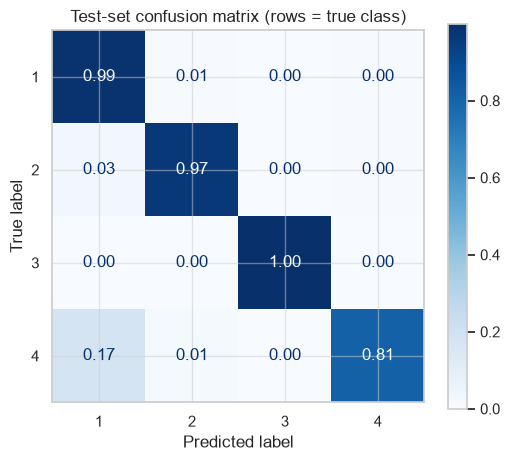

In [37]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", cmap="Blues", ax=ax, values_format=".2f")
ax.set_title("Test-set confusion matrix (rows = true class)")
plt.show()